# Battery fleet investigator

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ThomasAko/battery-fit-agent/blob/main/notebooks/colab_investigator.ipynb)

This notebook runs the **investigator mode** of `battery-fit-agent` on all 139 Severson fast-charge cells, and keeps
the full record of what the agent did:

1. **Fit** seven degradation laws to every cell (deterministic tools, no LLM).
2. **Triage** each cell against the fleet and build a shortlist.
3. **Investigate** each shortlisted cell with a tool-using LLM agent. The agent chooses which tools to call and
   when it knows enough, then gives a structured verdict. A deterministic verifier checks the verdict against the
   tool results and sends it back once if they disagree.
4. **Report** from the verdicts, and score the verdicts against hand labels and a rule-based baseline.

Runs in Google Colab or in Jupyter from the repository. Works with Groq (free tier), Gemini, Claude, OpenRouter or a
local Ollama model; set the provider below. In Colab, store the API key as a secret (key icon in the left sidebar)
named as in the table below.

| Provider | Secret / environment variable | Notes |
|---|---|---|
| `groq` | `GROQ_API_KEY` | free tier at console.groq.com; GPT OSS 120B by default |
| `gemini` | `GOOGLE_API_KEY` | aistudio.google.com; also reads the plots |
| `anthropic` | `ANTHROPIC_API_KEY` | platform.claude.com; also reads the plots |
| `openrouter` | `OPENROUTER_API_KEY` | needs a model id |
| `ollama` | none | local only, not in Colab |

## Setup

In [14]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git clone -q https://github.com/ThomasAko/battery-fit-agent.git
    %cd battery-fit-agent
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    %cd ..
print("working directory:", os.getcwd())

/content/battery-fit-agent/battery-fit-agent/battery-fit-agent/battery-fit-agent/battery-fit-agent
working directory: /content/battery-fit-agent/battery-fit-agent/battery-fit-agent/battery-fit-agent/battery-fit-agent


In [15]:
import os
PROVIDER = "groq"      # groq | gemini | anthropic | openrouter | ollama
MODEL    = None        # None = provider default (see battery_fit_agent/llm.py)
RPM      = 2           # max requests per minute: ~2 for Groq's free tier, 8 for Gemini free, 20+ for paid APIs
WHICH    = "labelled"  # "labelled" (the 10 hand-labelled cells), "high" (high-priority shortlist) or "all"

from battery_fit_agent.llm import _KEYS
key_name = _KEYS.get(PROVIDER)
if key_name and not os.getenv(key_name):
    if IN_COLAB:
        from google.colab import userdata
        os.environ[key_name] = userdata.get(key_name)
    else:
        from getpass import getpass
        os.environ[key_name] = getpass(f"{key_name}: ")
print("provider:", PROVIDER, "| key set:", bool(key_name is None or os.getenv(key_name)))

provider: groq | key set: True


## The agent

The outer workflow (fit, triage, investigate each cell, report) and, inside `investigate`, the investigator agent:
a loop between the model and its tools, then a structured verdict and a verifier.

model: openai/gpt-oss-120b


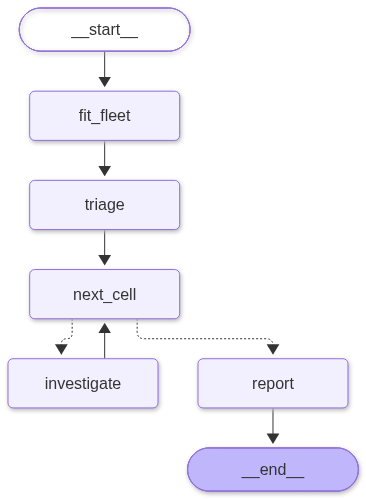

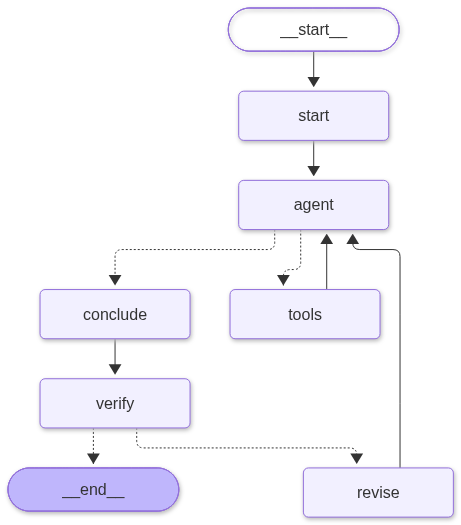

In [16]:
import os
import pandas as pd
from IPython.display import Markdown, Image, display
from battery_fit_agent import Config
from battery_fit_agent.llm import get_chat_model, supports_images
from battery_fit_agent.graph_v2 import build_fleet_agent
from battery_fit_agent.investigator import build_investigator

llm = get_chat_model(PROVIDER, MODEL, requests_per_minute=RPM or None)
print("model:", getattr(llm, "model", None) or getattr(llm, "model_name", None))

cfg = Config(out_dir="agent_outputs_investigator"); cfg.make_dirs()
labels = pd.read_csv("results/manual_labels.csv")
agent = build_fleet_agent(cfg, llm, which="cells" if WHICH == "labelled" else WHICH,
                          cells=labels["cell_id"].tolist() if WHICH == "labelled" else None,
                          send_plot=supports_images(PROVIDER),
                          skip_fit=os.path.exists(f"{cfg.out_dir}/summary.csv"))
for g in (agent.get_graph(), build_investigator(llm, []).get_graph()):
    try:
        display(Image(g.draw_mermaid_png()))     # rendered via mermaid.ink (needs internet)
    except Exception:
        print(g.draw_mermaid())

## Run

Fitting all 139 cells takes a few minutes (skipped if fits from an earlier run exist). The investigation makes
roughly 6–8 model calls per cell; at `RPM = 2` that is about 3–4 minutes per cell.

In [17]:
final = agent.invoke({"queue": [], "verdicts": [], "report": "", "shortlist": []}, {"recursion_limit": 500})
verdicts = pd.DataFrame(final["verdicts"])
verdicts[["cell_id", "category", "confidence", "tool_calls", "revised", "baseline"]]

Reusing fits in agent_outputs_investigator

Triage: 31/139 flagged, 7 high priority (fleet law: double_exp); investigating 10 cells
  FastCharge_000003_CH40: unusual_shape (high), 3 tool calls | baseline: unusual_shape
  FastCharge_000008_CH47: real_early_ageing (high), 3 tool calls, revised after verifier | baseline: real_early_ageing
  FastCharge_000026_CH5: real_early_ageing (high), 3 tool calls, revised after verifier | baseline: real_early_ageing
  FastCharge_000026_CH6: real_early_ageing (high), 4 tool calls, revised after verifier | baseline: real_early_ageing
  FastCharge_000041_CH10: real_early_ageing (high), 4 tool calls | baseline: real_early_ageing
  FastCharge_000045_CH1: test_ended_before_eol (high), 3 tool calls | baseline: data_quality
  FastCharge_000045_CH2: test_ended_before_eol (high), 2 tool calls | baseline: test_ended_before_eol
  FastCharge_000045_CH3: test_ended_before_eol (high), 3 tool calls | baseline: test_ended_before_eol
  FastCharge_000062_CH47: data_qua

,cell_id,category,confidence,tool_calls,revised,baseline
0,FastCharge_000003_CH40,unusual_shape,high,3,False,unusual_shape
1,FastCharge_000008_CH47,real_early_ageing,high,3,True,real_early_ageing
2,FastCharge_000026_CH5,real_early_ageing,high,3,True,real_early_ageing
3,FastCharge_000026_CH6,real_early_ageing,high,4,True,real_early_ageing
4,FastCharge_000041_CH10,real_early_ageing,high,4,False,real_early_ageing
5,FastCharge_000045_CH1,test_ended_before_eol,high,3,False,data_quality
6,FastCharge_000045_CH2,test_ended_before_eol,high,2,False,test_ended_before_eol
7,FastCharge_000045_CH3,test_ended_before_eol,high,3,False,test_ended_before_eol
8,FastCharge_000062_CH47,data_quality,high,4,False,unusual_shape
9,FastCharge_000068_CH38,unusual_shape,high,3,False,unusual_shape


## Triage: which cells were shortlisted, and why

In [18]:
triage = pd.read_csv(f"{cfg.out_dir}/summary_triage.csv")
print(f"{int(triage['flag'].sum())} of {len(triage)} cells flagged, "
      f"{int((triage['priority'] == 'high').sum())} high priority")
triage[triage["flag"]][["cell_id", "priority", "best_parametric", "knee_fraction", "fade_completed", "reasons"]]

31 of 139 cells flagged, 7 high priority


,cell_id,priority,best_parametric,knee_fraction,fade_completed,reasons
1,FastCharge_000001_CH16,medium,cubic,0.706,0.982,['degradation shape differs from the fleet (cu...
12,FastCharge_000003_CH40,medium,exponential,0.737,0.977,['exponential and double_exp statistically tie...
13,FastCharge_000004_CH1,medium,double_exp,0.715,0.965,['5 outlier cycles removed']
14,FastCharge_000004_CH2,medium,double_exp,0.518,0.995,['knee unusually early in life (at 52% of life...
15,FastCharge_000004_CH3,medium,double_exp,0.549,0.979,['knee unusually early in life (at 55% of life...
22,FastCharge_000006_CH43,medium,piecewise_1break,0.799,0.980,['degradation shape differs from the fleet (pi...
27,FastCharge_000008_CH47,high,cubic,0.690,0.980,['knee unusually early in life (at 69% of life...
38,FastCharge_000012_CH29,medium,piecewise_1break,0.783,0.986,['degradation shape differs from the fleet (pi...
42,FastCharge_000013_CH13,medium,double_exp,0.768,0.578,['test ended 58% of the way to end of life; kn...
46,FastCharge_000015_CH12,medium,piecewise_1break,0.783,0.990,['degradation shape differs from the fleet (pi...


## Verdicts and evidence

In [19]:
for _, v in verdicts.iterrows():
    display(Markdown(f"**{v.cell_id}**: `{v.category}` ({v.confidence} confidence), {v.tool_calls} tool calls"
                     + (", revised after the verifier" if v.revised else "") + "\n\n"
                     + "\n".join(f"- {e}" for e in v.evidence) + f"\n\n*Next step:* {v.recommended_action}"))

**FastCharge_000003_CH40**: `unusual_shape` (high confidence), 3 tool calls

- Best parametric law = exponential, runner‑up = double_exp, ΔBIC = 0.3 (statistically tied)
- Knee fraction = 0.737, fleet median = 0.783, cell percentile = 18.0 (earlier knee than most cells)
- Outliers removed = 0, recovery jumps = 0 (no data‑quality issues)
- Reached end of life: true, cycles = 703, q_end_Ah = 0.8845 (test completed, comparable to fleet)

*Next step:* Inspect the cell’s voltage and impedance trends to identify the physical cause of the mixed exponential/de‑double‑exponential fade behavior.

**FastCharge_000008_CH47**: `real_early_ageing` (high confidence), 3 tool calls, revised after the verifier

- Reached EOL: 616 cycles, q_end_Ah = 0.8841 Ah (98% of total fade completed) – check_end_of_life
- Knee at cycle 425 = 0.69 of life (knee_fraction_of_life), fleet median 0.783, cell percentile 5.8% – compare_to_fleet
- Knee z‑score = -3.48, far below fleet distribution – get_cell_overview

*Next step:* Flag the cell for early‑knee analysis and investigate fast‑fade mechanisms (e.g., SEI growth, lithium plating) in similar fast‑charge profiles.

**FastCharge_000026_CH5**: `real_early_ageing` (high confidence), 3 tool calls, revised after the verifier

- Reached end‑of‑life: true (209 cycles, q_end_Ah=0.8813 Ah)
- Knee at cycle 28 → knee_fraction=0.134, far below fleet median 0.783 (fleet 25‑75% 0.7525‑0.799)
- Knee Z‑score = -24.32 (extreme outlier)
- Best parametric law = cubic, ΔBIC vs runner‑up = 149, indicating a distinct degradation shape

*Next step:* Investigate early‑ageing mechanisms (e.g., fast‑charge stress, formation issues) and consider repeat testing or post‑mortem analysis.

**FastCharge_000026_CH6**: `real_early_ageing` (high confidence), 4 tool calls, revised after the verifier

- Knee occurs at cycle 168, which is 0.348 of total life (percentile 2.2% vs fleet median 0.783) – see compare_to_fleet output.
- Knee Z‑score = -16.3 (extremely early) – from get_cell_overview.
- Test reached true end‑of‑life: reached_end_of_life true, eol_cycle 483, fade_completed_fraction 0.9902 – from check_end_of_life.
- No outliers removed (outliers_removed = 0) – from get_cell_overview.

*Next step:* Prioritize this cell for detailed post‑mortem analysis to identify mechanisms causing the unusually early capacity fade.

**FastCharge_000041_CH10**: `real_early_ageing` (high confidence), 4 tool calls

- Knee occurs at cycle 93, which is 0.628 of total life (5th percentile of fleet, fleet median 0.783) – knee_fraction 0.628 vs fleet median 0.783, cell_percentile 5.0
- Knee z‑score = -5.81, far below typical values, triggering early‑knee shortlist reason
- Test reached end‑of‑life (eol_cycle 148, last_cycle 169) so the early knee is not due to early test termination

*Next step:* Flag the cell for deeper root‑cause analysis of early rapid fade and compare its formation/usage history to the fleet.

**FastCharge_000045_CH1**: `test_ended_before_eol` (high confidence), 3 tool calls

- fade_completed_fraction = 0.2415 (test stopped after only 24% of the way to EoL) (check_end_of_life)
- knee_cycle = 76 and knee_fraction_of_life = 0.068 (knee position based on only early part of life) (get_cell_overview)
- outliers_removed = 67 (many cycles removed, but test still ended early) (get_cell_overview)

*Next step:* Run the cell to its true end‑of‑life to obtain comparable knee and degradation‑shape metrics.

**FastCharge_000045_CH2**: `test_ended_before_eol` (high confidence), 2 tool calls

- Total cycles run: 1178 (check_end_of_life)
- Capacity fade completed: 0.1997 of total (check_end_of_life)
- Predicted cycles to EoL at recent rate: 3077.6 (check_end_of_life)
- Knee cycle: 409, which is 0.347 of projected life (get_cell_overview)

*Next step:* Continue cycling this cell until it reaches the 0.88 Ah end‑of‑life threshold to obtain comparable knee and degradation‑shape data.

**FastCharge_000045_CH3**: `test_ended_before_eol` (high confidence), 3 tool calls

- Test stopped at cycle 1176 with only 19.37% of the required capacity fade (fade_completed_fraction=0.1937) and projected ~3465 cycles to reach EOL
- Knee occurred at cycle 426, i.e., knee_fraction=0.362, far earlier than fleet median knee_fraction=0.783 (cell_percentile=2.9%)
- No outliers or recovery jumps were removed (outliers_removed=0, recovery_jumps=0)
- Best parametric law is power, but shape comparison is unreliable because the test ended early

*Next step:* Continue cycling this cell to its true end‑of‑life to obtain comparable knee and degradation‑shape metrics.

**FastCharge_000062_CH47**: `data_quality` (high confidence), 4 tool calls

- The test recorded 446 cycles and reached end‑of‑life at cycle 429 (eol_cycle=429).
- 4 outlier cycles were removed (outliers=4), far above the fleet median of 1 (cell_percentile=95.7).
- These outliers occur at cycles 447‑450, after the test end, and deviate by -28.3114 mAh from the trend.

*Next step:* Review the measurement setup for cycles 447‑450 and consider re‑testing or discarding this cell's data.

**FastCharge_000068_CH38**: `unusual_shape` (high confidence), 3 tool calls

- Best parametric law is "power" beating double_exp by ΔBIC=64.6, indicating a different degradation shape.
- Knee occurs at cycle 377, which is 0.789 of life (fleet median 0.783, percentile 62.6%).
- Test reached end‑of‑life (eol_cycle=478 of 500 cycles) with 3 outlier cycles removed, which are isolated.

*Next step:* Review the cell’s charge protocol and material batch to understand why a power‑law fits better than the fleet’s double‑exponential model.

## Agreement with hand labels

In [20]:
from battery_fit_agent.evaluate import evaluate
score, table = evaluate(verdicts, "results/manual_labels.csv")
print(score)
table

{'labelled_cells': 10, 'llm_agreement': '9/10', 'baseline_agreement': '10/10', 'skipped_api_errors': []}


,cell_id,label,category,confidence,baseline,llm_correct,baseline_correct
0,FastCharge_000003_CH40,unusual_shape,unusual_shape,high,unusual_shape,True,True
1,FastCharge_000008_CH47,real_early_ageing,real_early_ageing,high,real_early_ageing,True,True
2,FastCharge_000026_CH5,real_early_ageing,real_early_ageing,high,real_early_ageing,True,True
3,FastCharge_000026_CH6,real_early_ageing,real_early_ageing,high,real_early_ageing,True,True
4,FastCharge_000041_CH10,real_early_ageing,real_early_ageing,high,real_early_ageing,True,True
5,FastCharge_000045_CH1,data_quality,test_ended_before_eol,high,data_quality,True,True
6,FastCharge_000045_CH2,test_ended_before_eol,test_ended_before_eol,high,test_ended_before_eol,True,True
7,FastCharge_000045_CH3,test_ended_before_eol,test_ended_before_eol,high,test_ended_before_eol,True,True
8,FastCharge_000062_CH47,unusual_shape,data_quality,high,unusual_shape,False,True
9,FastCharge_000068_CH38,unusual_shape,unusual_shape,high,unusual_shape,True,True


## Report (written by the model from the verdicts only)

In [21]:
display(Markdown(final["report"]))

## Short‑list grouped by category  

| Category | Cells (evidence‑quoted numbers) |
|----------|---------------------------------|
| **real_early_ageing** | FastCharge_000008_CH47 – knee = 425 cycles, knee fraction = 0.69, percentile = 5.8 % (z‑score = ‑3.48); FastCharge_000026_CH5 – knee = 28 cycles, knee fraction = 0.134, percentile ≈ 0 % (z‑score = ‑24.32); FastCharge_000026_CH6 – knee = 168 cycles, knee fraction = 0.348, percentile = 2.2 % (z‑score = ‑16.3); FastCharge_000041_CH10 – knee = 93 cycles, knee fraction = 0.628, percentile = 5 % (z‑score = ‑5.81). |
| **unusual_shape** | FastCharge_000003_CH40 – ΔBIC = 0.3 (exponential vs double‑exp), knee fraction = 0.737, percentile = 18 %; FastCharge_000068_CH38 – ΔBIC = 64.6 (power vs double‑exp), knee fraction = 0.789, percentile = 62.6 %. |
| **data_quality** | FastCharge_000062_CH47 – outliers = 4 (95.7 % percentile), outlier deviation = ‑28.3114 mAh. |
| **test_ended_before_eol** | FastCharge_000045_CH1 – fade = 0.2415, knee fraction = 0.068, outliers = 67; FastCharge_000045_CH2 – fade = 0.1997, projected EoL = 3077.6 cycles, knee fraction = 0.347; FastCharge_000045_CH3 – fade = 0.1937, projected EoL ≈ 3465 cycles, knee fraction = 0.362. |

## Prioritisation  

1. **Real early‑ageing cells** – the knee occurs far earlier than the fleet median (0.783) with extreme z‑scores (‑3.48 to ‑24.32). These cells dominate capacity loss and merit immediate post‑mortem or accelerated‑ageing studies.  
2. **Unusual‑shape cells** – ΔBIC values (0.3 and 64.6) indicate degradation models that diverge from the fleet‑wide double‑exp law, suggesting distinct physicochemical pathways; they should be examined after the early‑ageing set.  
3. **Data‑quality issue** – a single cell shows 4 outliers (95.7 % percentile) with a large deviation (‑28.3114 mAh); verify measurement setup before deeper analysis.  
4. **Tests stopped early** – three cells only reached 19–24 % of the required fade; extending cycling is needed before any meaningful knee or shape comparison can be drawn.  

Focus first on the four early‑knee cells, then on the two shape‑anomalous cells, followed by data‑quality verification and finally completing the incomplete tests.

## Every investigation, step by step

Each trace shows the tools the model chose, what they returned, any verifier feedback, and the final verdict.

# FastCharge_000003_CH40

**call** `get_cell_overview({"cell_id": "FastCharge_000003_CH40"})`

```json
{"cell_id": "FastCharge_000003_CH40", "cycles": 703, "eol_cycle": 703, "reached_end_of_life": true, "q_start_Ah": 1.0734, "q_end_Ah": 0.8845, "noise_mAh": 0.15, "knee_cycle": 518, "knee_fraction_of_life": 0.737, "outliers_removed": 0, "recovery_jumps": 0, "best_parametric_law": "exponential", "runner_up": "double_exp", "delta_bic_runner_up": 0.3, "misfit_z": 0.21, "knee_z": -1.72, "shortlist_reasons": ["exponential and double_exp statistically tied (dBIC=0.3)"]}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000003_CH40", "metric": "knee_fraction_of_life"})`

```json
{"error": "metric must be one of ['knee_fraction', 'rmse_mAh', 'noise_mAh', 'cycles', 'eol_cycle', 'fade_rate_mAh_per_100', 'outliers']"}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000003_CH40", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.737, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 18.0, "n_cells": 139}
```

**agent:** **Category:** unusual_shape  

**Why this cell stands out**

| Item | Value (from the tools) | Fleet comparison / significance |
|------|------------------------|---------------------------------|
| **Best parametric law** | *exponential* | – |
| **Runner‑up law** | *double_exp* | – |
| **Δ BIC (runner‑up vs. best)** | **0.3** | A Δ BIC < 2 means the two models are statistically indistinguishable. The fleet almost always shows a clear winner; here the exponential and double‑exponential fits are tied, which is unusual. |
| **Knee cycle** | **518** (out of 703 total cycles) | **Knee‑fraction = 0.737** |
| **Fleet knee‑fraction median** | 0.783 (25 %‑75 % = 0.7525‑0.799) | The cell’s knee occurs **earlier** than the fleet median (percentile ≈ 18 %). It is earlier than most cells, but the primary reason it was shortlisted is the tied‑law situation, not just the early knee. |
| **Outliers removed** | 0 | No data‑quality flags. |
| **Reached end‑of‑life?** | Yes (703 cycles, 0.884 Ah) | Test completed, so the knee is comparable to the fleet. |
| **Shortlist reason (provided by the system)** | “exponential and double_exp statistically tied (dBIC=0.3)” | Directly points to an unusual degradation‑law fit. |

**Interpretation**

The cell’s degradation follows a pattern that cannot be cleanly described by a single parametric law. In the fleet, the exponential law (or another single law) usually dominates with a clear BIC advantage. Here the exponential and double‑exponential models are essentially tied (Δ BIC = 0.3), indicating that the cell’s capacity fade does not conform to the typical single‑law behavior. This ambiguity in the best‑fit law is what makes the cell stand out on the shortlist.

While the knee also occurs a bit earlier than most cells (≈ 18 th percentile), the decisive factor is the statistical tie between two competing degradation models, which is a hallmark of an **unusual shape** of the fade curve. No outliers, gaps, or premature test termination are present, and the test reached true end‑of‑life, so data‑quality or early‑ageing categories do not apply.

**verdict:** `{
 "category": "unusual_shape",
 "confidence": "high",
 "evidence": [
  "Best parametric law = exponential, runner\u2011up = double_exp, \u0394BIC = 0.3 (statistically tied)",
  "Knee fraction = 0.737, fleet median = 0.783, cell percentile = 18.0 (earlier knee than most cells)",
  "Outliers removed = 0, recovery jumps = 0 (no data\u2011quality issues)",
  "Reached end of life: true, cycles = 703, q_end_Ah = 0.8845 (test completed, comparable to fleet)"
 ],
 "recommended_action": "Inspect the cell\u2019s voltage and impedance trends to identify the physical cause of the mixed exponential/de\u2011double\u2011exponential fade behavior."
}`


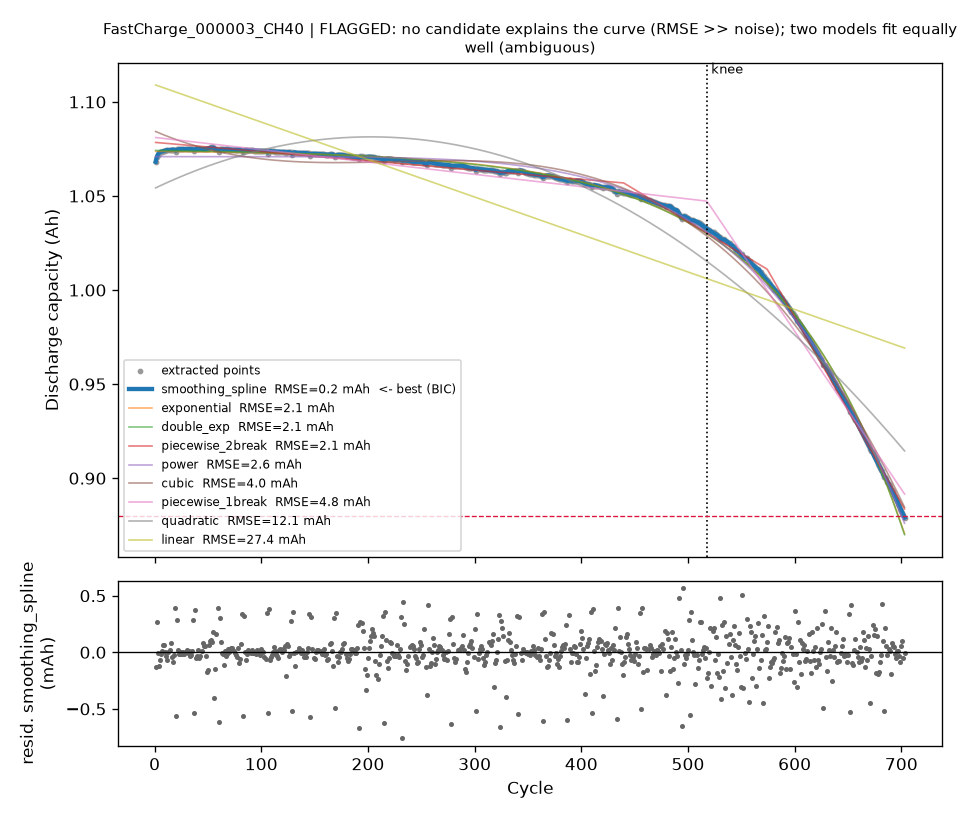

---

# FastCharge_000008_CH47

**call** `get_cell_overview({"cell_id": "FastCharge_000008_CH47"})`

```json
{"cell_id": "FastCharge_000008_CH47", "cycles": 616, "eol_cycle": 616, "reached_end_of_life": true, "q_start_Ah": 1.0874, "q_end_Ah": 0.8841, "noise_mAh": 0.16, "knee_cycle": 425, "knee_fraction_of_life": 0.69, "outliers_removed": 0, "recovery_jumps": 0, "best_parametric_law": "cubic", "runner_up": "power", "delta_bic_runner_up": 112.4, "misfit_z": 0.73, "knee_z": -3.48, "shortlist_reasons": ["knee unusually early in life (at 69% of life, z=-3.48)", "degradation shape differs from the fleet (cubic beats double_exp by dBIC=189.4)"]}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000008_CH47", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.69, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 5.8, "n_cells": 139}
```

**agent:** **Category:** real_early_ageing  

**Why this cell stands out**

- The test reached its end‑of‑life (616 cycles, capacity 0.884 Ah ≈ 80 % of start).  
- Its capacity‑fade “knee” occurs at cycle 425, which is only **69 % of its total life**.  
- Compared with the fleet, the knee‑fraction percentile is **5.8 %** (fleet median ≈ 0.78, 25‑th ≈ 0.75).  
- The knee‑z‑score is **‑3.48**, indicating the knee appears far earlier than typical fleet behavior.  

These numbers show the cell entered its rapid‑fade region unusually early, matching the “real_early_ageing” category. No outliers or data‑quality issues are present, and the test completed the full life, so other categories do not apply.

**verifier:** A consistency check found problems with your verdict:
- 'real_early_ageing' requires check_end_of_life, which you did not call
Use the tools as needed and reconsider.

**call** `check_end_of_life({"cell_id": "FastCharge_000008_CH47"})`

```json
{"reached_end_of_life": true, "eol_cycle": 616, "last_cycle": 616, "q_end_Ah": 0.8841, "fade_completed_fraction": 0.9802, "recent_fade_mAh_per_100_cycles": 103.1976, "cycles_to_end_of_life_at_recent_rate": null}
```

**agent:** **Category:** real_early_ageing  

**Why this cell stands out**

- **End‑of‑life reached:** The test ran to 616 cycles, ending at 0.884 Ah (≈ 80 % of the start capacity). `check_end_of_life` confirms the cell reached EOL and that **98 % of the total capacity fade** was completed (`fade_completed_fraction = 0.9802`).  
- **Early knee:** The capacity‑fade knee occurs at cycle 425, which is **69 % of the total life** (`knee_fraction_of_life = 0.69`).  
- **Fleet comparison:** Against the fleet, the knee‑fraction percentile is **5.8 %** (fleet median ≈ 0.78, 25‑th ≈ 0.75). The knee‑z‑score is **‑3.48**, showing the knee appears far earlier than typical cells.  
- **No data‑quality flags:** No outliers or measurement jumps were removed, and the test completed the full life, so the early knee is not due to a truncated test or data issues.

**Conclusion:** The cell entered its rapid‑fade region unusually early in its life, satisfying the “real_early_ageing” category.

**verdict:** `{
 "category": "real_early_ageing",
 "confidence": "high",
 "evidence": [
  "Reached EOL: 616 cycles, q_end_Ah = 0.8841 Ah (98% of total fade completed) \u2013 check_end_of_life",
  "Knee at cycle 425 = 0.69 of life (knee_fraction_of_life), fleet median 0.783, cell percentile 5.8% \u2013 compare_to_fleet",
  "Knee z\u2011score = -3.48, far below fleet distribution \u2013 get_cell_overview"
 ],
 "recommended_action": "Flag the cell for early\u2011knee analysis and investigate fast\u2011fade mechanisms (e.g., SEI growth, lithium plating) in similar fast\u2011charge profiles."
}`


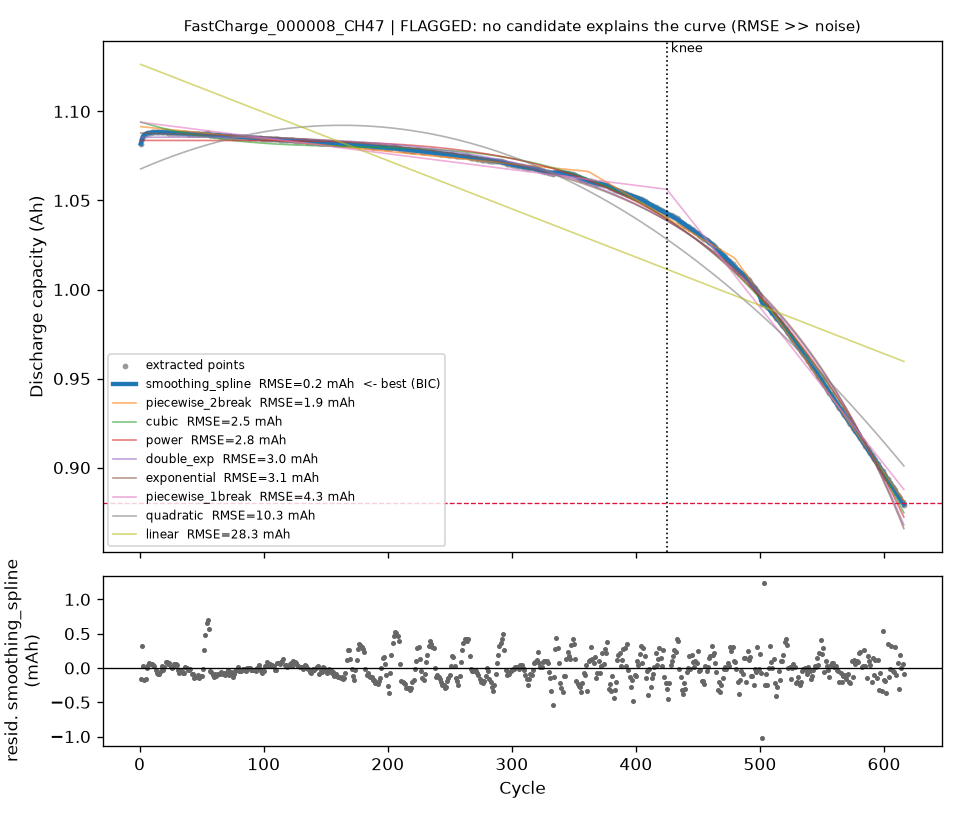

---

# FastCharge_000026_CH5

**call** `get_cell_overview({"cell_id": "FastCharge_000026_CH5"})`

```json
{"cell_id": "FastCharge_000026_CH5", "cycles": 209, "eol_cycle": 209, "reached_end_of_life": true, "q_start_Ah": 0.9697, "q_end_Ah": 0.8813, "noise_mAh": 0.49, "knee_cycle": 28, "knee_fraction_of_life": 0.134, "outliers_removed": 0, "recovery_jumps": 0, "best_parametric_law": "cubic", "runner_up": "piecewise_1break", "delta_bic_runner_up": 149.0, "misfit_z": -1.64, "knee_z": -24.32, "shortlist_reasons": ["knee unusually early in life (at 13% of life, z=-24.32)", "degradation shape differs from the fleet (cubic beats double_exp by dBIC=314.2)"]}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000026_CH5", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.134, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 0.7, "n_cells": 139}
```

**agent:** **Category:** real_early_ageing  

**Why this cell stands out**

| Item | Value (cell) | Fleet reference | Comment |
|------|--------------|----------------|---------|
| **Reached end‑of‑life** | Yes (209 cycles, 0.881 Ah) | – | The test ran to the 80 % capacity limit, so the knee is comparable to the fleet. |
| **Knee cycle** | 28 cycles | – | This is only **13 % of the cell’s total life**. |
| **Knee‑fraction of life** | **0.134** | Fleet median 0.783 (25‑75 % ≈ 0.75‑0.80) | The cell’s knee occurs far earlier than any typical cell. |
| **Knee Z‑score** | **‑24.32** | – | An extreme outlier (far below the fleet distribution). |
| **Outliers / data gaps** | 0 removed, 0 recovery jumps | – | No data‑quality issues that could explain the early knee. |
| **Degradation shape** | Best fit = cubic (ΔBIC vs runner‑up = 149) | Fleet usually follows double‑exp or piecewise laws | The shape also differs, reinforcing that the cell behaves unusually. |

Because the cell **reached its end‑of‑life** and its **knee (fast‑fade onset) appears at only 13 % of its life**, far earlier than the fleet median (≈78 %) with an extreme Z‑score, the primary reason for its shortlist is an **early onset of rapid capacity loss**. This matches the definition of **real_early_ageing**.

**verifier:** A consistency check found problems with your verdict:
- 'real_early_ageing' requires check_end_of_life, which you did not call
Use the tools as needed and reconsider.

**call** `check_end_of_life({"cell_id": "FastCharge_000026_CH5"})`

```json
{"reached_end_of_life": true, "eol_cycle": 209, "last_cycle": 209, "q_end_Ah": 0.8813, "fade_completed_fraction": 0.9855, "recent_fade_mAh_per_100_cycles": 45.5617, "cycles_to_end_of_life_at_recent_rate": null}
```

**agent:** **Re‑evaluation (with `check_end_of_life`)**

The `check_end_of_life` call shows:

- **Reached end‑of‑life:** true (209 cycles, 0.881 Ah)  
- **Fade completed:** 98.5 % of the total 80 %‑capacity fade  
- **Recent fade rate:** ≈ 45 mAh per 100 cycles (normal for the fleet)  

Thus the test **did reach the end‑of‑life point**, so the knee position can be compared directly to the fleet.

**Key facts (from `get_cell_overview` and `compare_to_fleet`)**

| Metric | Cell | Fleet median | Fleet 25‑75 % | Cell percentile |
|--------|------|--------------|--------------|-----------------|
| Knee fraction of life | **0.134** (28 cycles / 209 cycles) | 0.783 | 0.752 – 0.799 | 0.7 % |
| Knee Z‑score | **‑24.32** | – | – | – |
| Outliers removed | 0 | – | – | – |
| Best parametric law | **cubic** (ΔBIC = 149 vs runner‑up) | Fleet usually double‑exp/piecewise | – | – |

**Interpretation**

- The cell **reached EOL**, so the early knee is not an artifact of a prematurely stopped test.  
- Its knee occurs at **13 % of its total life**, far earlier than the fleet median (~78 %).  
- The extreme knee Z‑score (‑24.32) and the distinct degradation law (cubic) confirm the cell’s behavior is atypical.

**Conclusion**

The cell’s standout characteristic is an **unusually early onset of rapid capacity fade**, satisfying the definition of **`real_early_ageing`**. No data‑quality issues or early test termination are present.

**verdict:** `{
 "category": "real_early_ageing",
 "confidence": "high",
 "evidence": [
  "Reached end\u2011of\u2011life: true (209 cycles, q_end_Ah=0.8813 Ah)",
  "Knee at cycle 28 \u2192 knee_fraction=0.134, far below fleet median 0.783 (fleet 25\u201175% 0.7525\u20110.799)",
  "Knee Z\u2011score = -24.32 (extreme outlier)",
  "Best parametric law = cubic, \u0394BIC vs runner\u2011up = 149, indicating a distinct degradation shape"
 ],
 "recommended_action": "Investigate early\u2011ageing mechanisms (e.g., fast\u2011charge stress, formation issues) and consider repeat testing or post\u2011mortem analysis."
}`


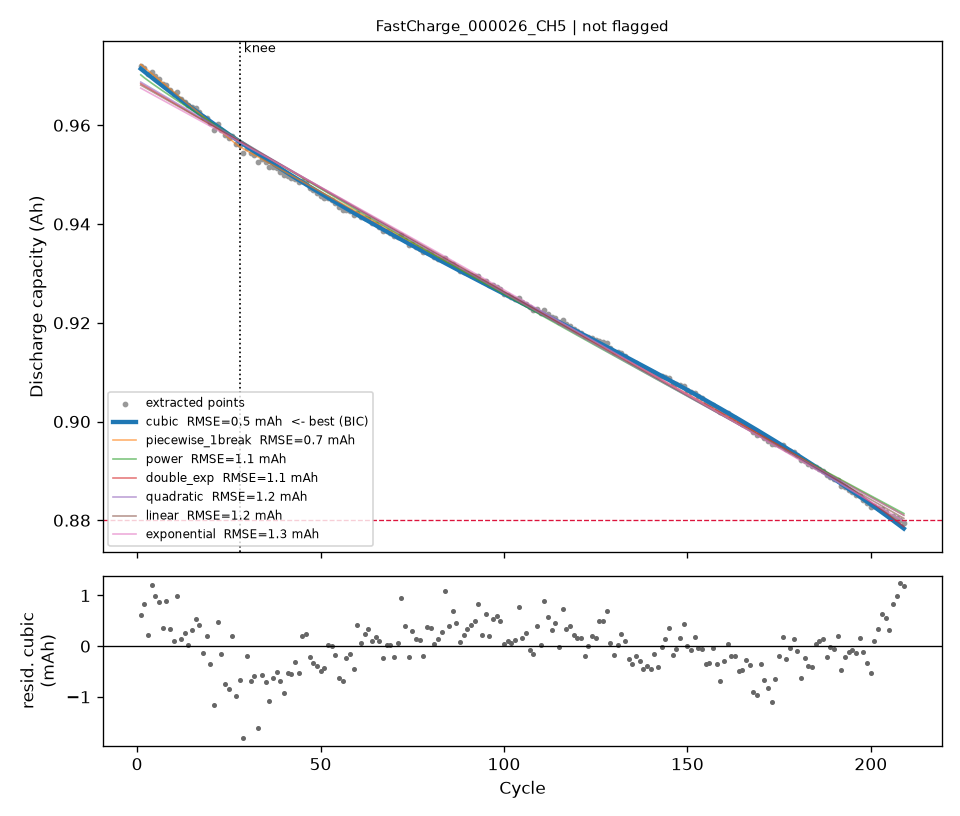

---

# FastCharge_000026_CH6

**call** `get_cell_overview({"cell_id": "FastCharge_000026_CH6"})`

```json
{"cell_id": "FastCharge_000026_CH6", "cycles": 483, "eol_cycle": 483, "reached_end_of_life": true, "q_start_Ah": 1.012, "q_end_Ah": 0.8813, "noise_mAh": 0.37, "knee_cycle": 168, "knee_fraction_of_life": 0.348, "outliers_removed": 0, "recovery_jumps": 0, "best_parametric_law": "cubic", "runner_up": "power", "delta_bic_runner_up": 707.4, "misfit_z": -1.38, "knee_z": -16.3, "shortlist_reasons": ["knee unusually early in life (at 35% of life, z=-16.3)", "degradation shape differs from the fleet (cubic beats double_exp by dBIC=1152.3)"]}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000026_CH6", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.348, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 2.2, "n_cells": 139}
```

**call** `get_fit_table({"cell_id": "FastCharge_000026_CH6"})`

```json
{"cubic": {"rmse_mAh": 0.72, "r2": 0.9997, "bic": -6968.7, "delta_bic": 0.0}, "power": {"rmse_mAh": 1.5, "r2": 0.9987, "bic": -6261.3, "delta_bic": 707.4}, "piecewise_1break": {"rmse_mAh": 1.66, "r2": 0.9984, "bic": -6158.5, "delta_bic": 810.2}, "quadratic": {"rmse_mAh": 1.99, "r2": 0.9977, "bic": -5989.4, "delta_bic": 979.3}, "double_exp": {"rmse_mAh": 2.37, "r2": 0.9967, "bic": -5816.4, "delta_bic": 1152.3}, "exponential": {"rmse_mAh": 2.8, "r2": 0.9954, "bic": -5660.0, "delta_bic": 1308.7}, "linear": {"rmse_mAh": 7.84, "r2": 0.9642, "bic": -4671.2, "delta_bic": 2297.5}}
```

**agent:** **Cell:** FastCharge_000026_CH6  

**Why it stands out**

| Indicator | Value (cell) | Fleet reference | Interpretation |
|-----------|--------------|----------------|----------------|
| **Knee cycle** | 168 cycles | – | The knee occurs at **35 % of the cell’s total life** (483 cycles). |
| **Knee‑fraction of life** | 0.348 | Median ≈ 0.783 (25 %‑75 % ≈ 0.753‑0.799) | The cell is in the **2.2 nd percentile** of the fleet – far earlier than typical. |
| **Knee Z‑score** | **‑16.3** | – | Extremely early (the shortlist flagged this). |
| **Outliers** | 0 removed | – | No data‑quality issues. |
| **Best parametric law** | **cubic** (RMSE 0.72 mAh, BIC ‑6968.7) | – | The cubic law beats the double‑exponential (the usual fleet law) by **ΔBIC ≈ 1152**, showing a **different degradation shape**. |
| **Reached end‑of‑life?** | Yes (EOL at 483 cycles, Q_end = 0.881 Ah) | – | The test ran to the 80 % capacity point, so the early knee is not due to an early‑stop test. |

**Conclusion – Category:** **real_early_ageing**  

The cell’s knee appears at only 35 % of its life (knee‑fraction = 0.348, percentile ≈ 2 %), far earlier than the fleet median (≈ 78 %). The knee Z‑score (‑16.3) confirms an unusually early onset of rapid capacity fade. The test reached true end‑of‑life, and there are no outliers, so the standout behavior is genuine early ageing rather than a data‑quality or premature‑test issue. (A secondary observation is that its degradation follows a cubic law rather than the fleet’s typical double‑exponential, but the primary flag is the early knee.)

**verifier:** A consistency check found problems with your verdict:
- 'real_early_ageing' requires check_end_of_life, which you did not call
Use the tools as needed and reconsider.

**call** `check_end_of_life({"cell_id": "FastCharge_000026_CH6"})`

```json
{"reached_end_of_life": true, "eol_cycle": 483, "last_cycle": 483, "q_end_Ah": 0.8813, "fade_completed_fraction": 0.9902, "recent_fade_mAh_per_100_cycles": 41.542, "cycles_to_end_of_life_at_recent_rate": null}
```

**agent:** **Cell:** FastCharge_000026_CH6  

**Verification of end‑of‑life**  
`check_end_of_life` reports:

* Reached end‑of‑life: **true**  
* EOL cycle: 483 (same as the test’s last cycle)  
* Fade completed fraction: 0.990 ≈ 99 % of the capacity loss to the 80 % threshold has occurred  

Thus the test ran to true end‑of‑life; the early knee is not an artefact of a prematurely stopped test.

**Why the cell is flagged**

| Metric | Cell value | Fleet reference | Interpretation |
|--------|------------|----------------|----------------|
| **Knee cycle** | 168 cycles | – | Occurs at **35 % of the cell’s total life** (483 cycles). |
| **Knee‑fraction of life** | 0.348 | Median ≈ 0.783 (25‑75 % ≈ 0.753‑0.799) | **2.2 nd percentile** of the fleet – far earlier than normal. |
| **Knee Z‑score** | **‑16.3** | – | Extremely early; the shortlist flagged “knee unusually early (z = ‑16.3)”. |
| **Outliers** | 0 removed | – | No data‑quality issues. |
| **Best parametric law** | **cubic** (RMSE 0.72 mAh, BIC ‑6968.7) | – | Beats the fleet‑typical double‑exponential by **ΔBIC ≈ 1152**, indicating a **different degradation shape**. |
| **Reached EOL?** | Yes (EOL at 483 cycles, Q_end = 0.881 Ah) | – | Confirms the early knee is not due to an early‑stop test. |

**Category determination**

- The cell **reached true end‑of‑life** (check_end_of_life confirms 99 % of the fade completed).  
- Its knee appears at only **35 % of its life**, placing it in the **2 nd percentile** of the fleet with a very large negative Z‑score.  
- No outliers or measurement gaps are present.

Therefore the cell’s standout behavior matches the definition of **real_early_ageing**: an unusually early onset of rapid capacity fade that is not caused by an early‑stopped test or data‑quality problems.

**Result:** **real_early_ageing** (early knee) – with a secondary note that its degradation follows a cubic law rather than the fleet’s usual double‑exponential, but the primary issue is the early ageing.

**verdict:** `{
 "category": "real_early_ageing",
 "confidence": "high",
 "evidence": [
  "Knee occurs at cycle 168, which is 0.348 of total life (percentile 2.2% vs fleet median 0.783) \u2013 see compare_to_fleet output.",
  "Knee Z\u2011score = -16.3 (extremely early) \u2013 from get_cell_overview.",
  "Test reached true end\u2011of\u2011life: reached_end_of_life true, eol_cycle 483, fade_completed_fraction 0.9902 \u2013 from check_end_of_life.",
  "No outliers removed (outliers_removed = 0) \u2013 from get_cell_overview."
 ],
 "recommended_action": "Prioritize this cell for detailed post\u2011mortem analysis to identify mechanisms causing the unusually early capacity fade."
}`


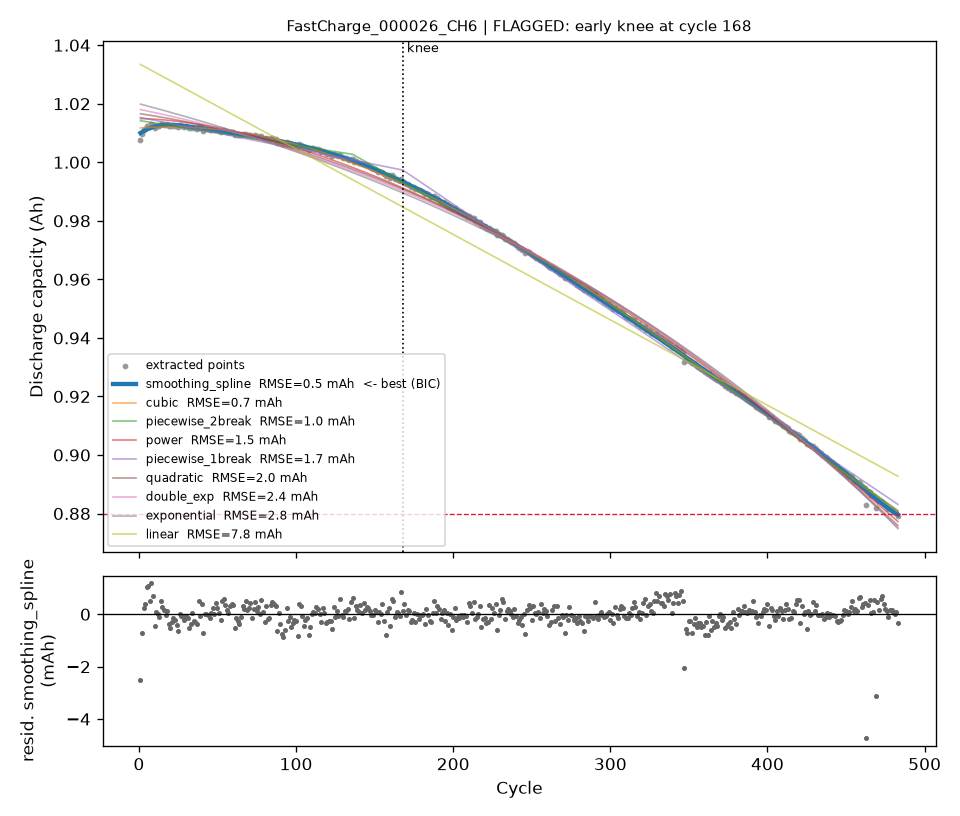

---

# FastCharge_000041_CH10

**call** `get_cell_overview({"cell_id": "FastCharge_000041_CH10"})`

```json
{"cell_id": "FastCharge_000041_CH10", "cycles": 169, "eol_cycle": 148, "reached_end_of_life": true, "q_start_Ah": 1.0714, "q_end_Ah": 0.8407, "noise_mAh": 1.66, "knee_cycle": 93, "knee_fraction_of_life": 0.628, "outliers_removed": 2, "recovery_jumps": 0, "best_parametric_law": "cubic", "runner_up": "double_exp", "delta_bic_runner_up": 6.5, "misfit_z": -1.02, "knee_z": -5.81, "shortlist_reasons": ["knee unusually early in life (at 63% of life, z=-5.81)"]}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000041_CH10", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.628, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 5.0, "n_cells": 139}
```

**call** `locate_outliers({"cell_id": "FastCharge_000041_CH10"})`

```json
{"outliers": 2, "per_quarter_of_test": [0, 0, 0, 0], "first_cycle": 170.0, "last_cycle": 171.0, "fraction_below_trend": 1.0, "median_deviation_mAh": -23.2692, "recovery_jumps": 0}
```

**call** `check_end_of_life({"cell_id": "FastCharge_000041_CH10"})`

```json
{"reached_end_of_life": true, "eol_cycle": 148, "last_cycle": 169, "q_end_Ah": 0.8407, "fade_completed_fraction": 1.2053, "recent_fade_mAh_per_100_cycles": 209.6146, "cycles_to_end_of_life_at_recent_rate": null}
```

**agent:** **Cell:** FastCharge_000041_CH10  

**Why it was shortlisted:** The knee (the point where capacity loss suddenly accelerates) occurs at 93 cycles, which is only 62.8 % of the cell’s total life.  

**Evidence**

| Metric | Cell value | Fleet median | Fleet 25‑%‑75 % | Cell percentile |
|--------|------------|--------------|----------------|-----------------|
| Knee‑fraction of life | **0.628** | 0.783 | 0.752 – 0.799 | **5 %** |
| Knee‑z‑score | **‑5.81** (very low) | – | – | – |

* The cell’s knee‑fraction is far below the fleet distribution (5 th percentile), giving a knee‑z‑score of –5.81, which triggered the “knee unusually early” shortlist reason.  

**End‑of‑life check**

* The test **did reach end‑of‑life** (capacity fell to 0.84 Ah, below the 0.88 Ah EOL threshold).  
* The recorded end‑of‑life cycle is 148, and the test continued to 169 cycles, so the early knee is not an artifact of stopping the test early.  

**Outlier assessment**

* Two outlier points were identified, both occurring **after the test’s nominal end (cycles 170‑171)**.  
* No outliers appear within the main test window (all quarters show 0), and the outliers are isolated, not clustered.  
* Their presence does not dominate the capacity‑fade trend.  

**Conclusion**

The cell’s **knee appears far earlier than the rest of the fleet**, and the test ran well past the true end‑of‑life, confirming that the early acceleration is genuine rather than a data‑quality or premature‑stop issue.

**Category:** **real_early_ageing** – the cell reaches its rapid‑fade knee unusually early in its life.

**verdict:** `{
 "category": "real_early_ageing",
 "confidence": "high",
 "evidence": [
  "Knee occurs at cycle 93, which is 0.628 of total life (5th percentile of fleet, fleet median 0.783) \u2013 knee_fraction 0.628 vs fleet median 0.783, cell_percentile 5.0",
  "Knee z\u2011score = -5.81, far below typical values, triggering early\u2011knee shortlist reason",
  "Test reached end\u2011of\u2011life (eol_cycle 148, last_cycle 169) so the early knee is not due to early test termination"
 ],
 "recommended_action": "Flag the cell for deeper root\u2011cause analysis of early rapid fade and compare its formation/usage history to the fleet."
}`


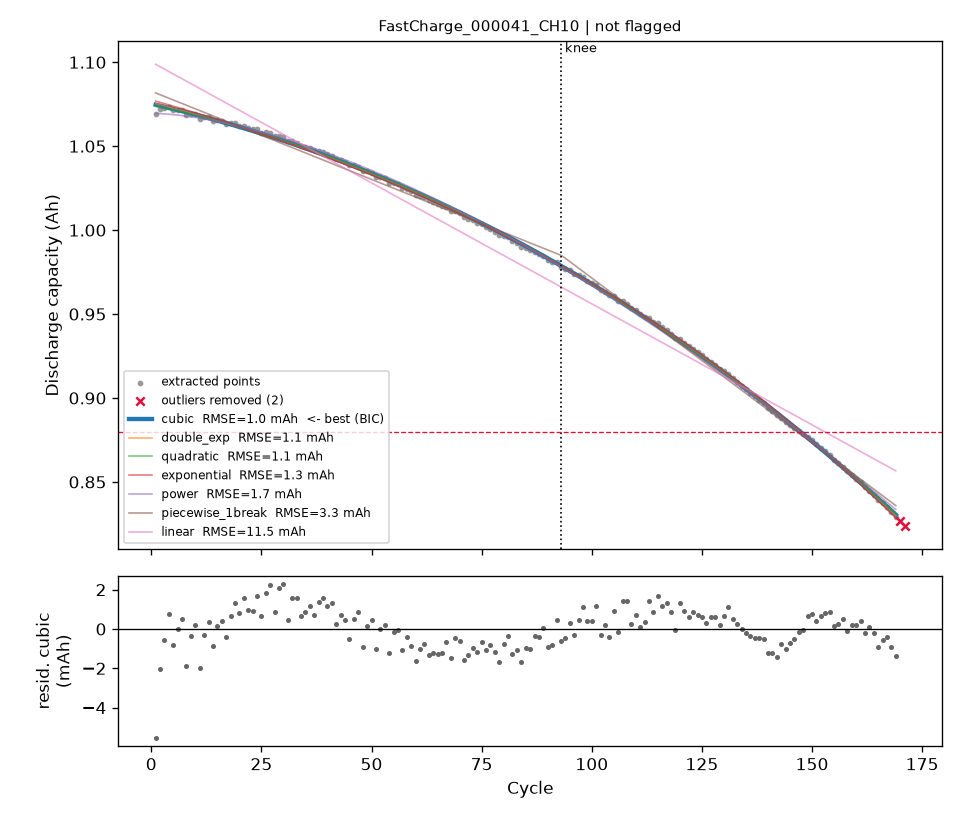

---

# FastCharge_000045_CH1

**call** `get_cell_overview({"cell_id": "FastCharge_000045_CH1"})`

```json
{"cell_id": "FastCharge_000045_CH1", "cycles": 1122, "eol_cycle": null, "reached_end_of_life": false, "q_start_Ah": 1.0734, "q_end_Ah": 1.0267, "noise_mAh": 0.66, "knee_cycle": 76, "knee_fraction_of_life": 0.068, "outliers_removed": 67, "recovery_jumps": 6, "best_parametric_law": "piecewise_1break", "runner_up": "power", "delta_bic_runner_up": 30.7, "misfit_z": 0.93, "knee_z": null, "shortlist_reasons": ["test ended 24% of the way to end of life; knee position not comparable", "degradation shape differs from the fleet (piecewise_1break beats double_exp by dBIC=62.5)", "67 outlier cycles removed", "6 capacity-recovery jumps"]}
```

**call** `check_end_of_life({"cell_id": "FastCharge_000045_CH1"})`

```json
{"reached_end_of_life": false, "eol_cycle": null, "last_cycle": 1189, "q_end_Ah": 1.0267, "fade_completed_fraction": 0.2415, "recent_fade_mAh_per_100_cycles": 7.6385, "cycles_to_end_of_life_at_recent_rate": 1920.5423}
```

**call** `locate_outliers({"cell_id": "FastCharge_000045_CH1"})`

```json
{"outliers": 67, "per_quarter_of_test": [3, 25, 39, 0], "first_cycle": 12.0, "last_cycle": 851.0, "fraction_below_trend": 0.9851, "median_deviation_mAh": -18.8633, "recovery_jumps": 6}
```

**agent:** **Category:** **test_ended_before_eol**

**Why this cell stands out**

- The test stopped after only **24 % of the fade needed to reach the 80 % capacity end‑of‑life point** (fade_completed_fraction = 0.2415).  
- Because the test ended so early, the **knee occurs at 76 cycles (≈ 6.8 % of the eventual life)**, a value that cannot be compared reliably with the fleet’s knee‑fraction distribution.  
- The shortlist explicitly notes: *“test ended 24 % of the way to end of life; knee position not comparable.”*  

While the cell also shows many outlier cycles (67 removed) and a degradation shape that differs from the fleet, those issues are secondary to the fact that the test never reached the end‑of‑life region, making any knee‑position or shape comparison non‑representative. Hence the appropriate classification is **test_ended_before_eol**.

**verdict:** `{
 "category": "test_ended_before_eol",
 "confidence": "high",
 "evidence": [
  "fade_completed_fraction = 0.2415 (test stopped after only 24% of the way to EoL) (check_end_of_life)",
  "knee_cycle = 76 and knee_fraction_of_life = 0.068 (knee position based on only early part of life) (get_cell_overview)",
  "outliers_removed = 67 (many cycles removed, but test still ended early) (get_cell_overview)"
 ],
 "recommended_action": "Run the cell to its true end\u2011of\u2011life to obtain comparable knee and degradation\u2011shape metrics."
}`


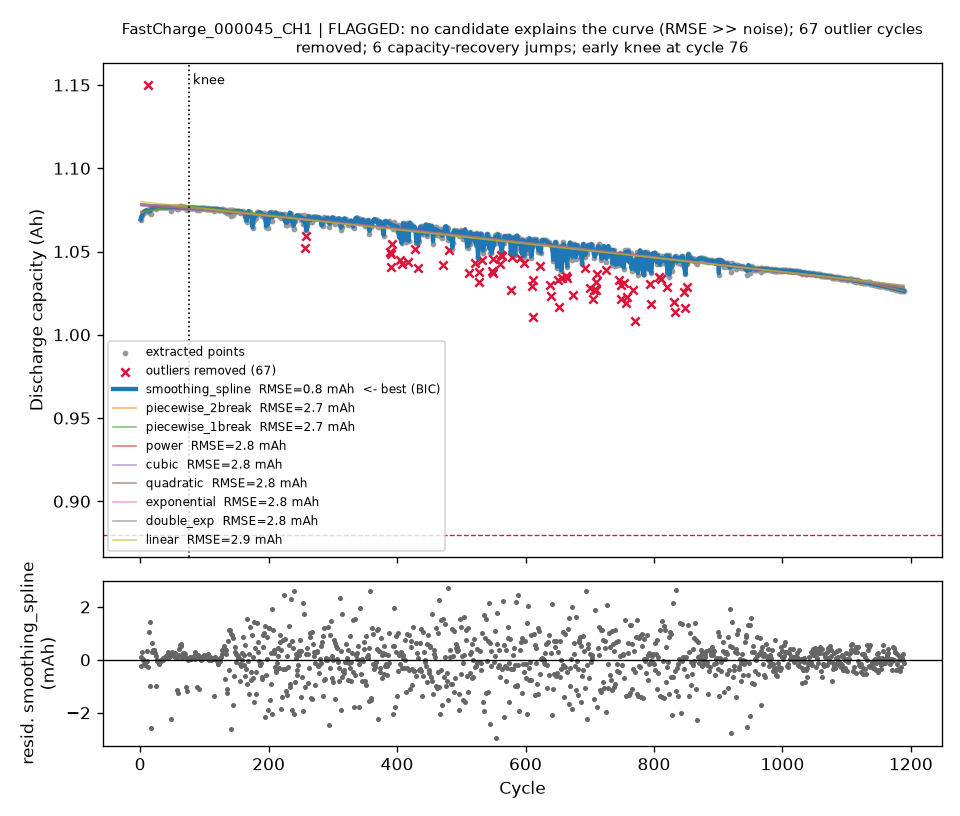

---

# FastCharge_000045_CH2

**call** `get_cell_overview({"cell_id": "FastCharge_000045_CH2"})`

```json
{"cell_id": "FastCharge_000045_CH2", "cycles": 1178, "eol_cycle": null, "reached_end_of_life": false, "q_start_Ah": 1.0783, "q_end_Ah": 1.0387, "noise_mAh": 0.1, "knee_cycle": 409, "knee_fraction_of_life": 0.347, "outliers_removed": 0, "recovery_jumps": 0, "best_parametric_law": "cubic", "runner_up": "power", "delta_bic_runner_up": 58.4, "misfit_z": -1.38, "knee_z": null, "shortlist_reasons": ["test ended 20% of the way to end of life; knee position not comparable", "degradation shape differs from the fleet (cubic beats double_exp by dBIC=400.4)"]}
```

**call** `check_end_of_life({"cell_id": "FastCharge_000045_CH2"})`

```json
{"reached_end_of_life": false, "eol_cycle": null, "last_cycle": 1178, "q_end_Ah": 1.0387, "fade_completed_fraction": 0.1997, "recent_fade_mAh_per_100_cycles": 5.1566, "cycles_to_end_of_life_at_recent_rate": 3077.638}
```

**agent:** **Cell:** FastCharge_000045_CH2  

**Why it was flagged:** The test stopped far short of the cell’s end‑of‑life (EoL) point, so the knee position and the degradation‑shape metrics cannot be compared directly with the rest of the fleet.

**Evidence**

| Metric | Value (from the tools) |
|--------|------------------------|
| Total cycles run | **1 178** |
| Capacity at start | **1.078 Ah** |
| Capacity at end of test | **1.039 Ah** |
| Fraction of capacity fade completed | **≈ 20 %** of the total fade needed to reach the 0.88 Ah EoL threshold |
| Predicted cycles remaining at the recent fade rate | **≈ 3 078** cycles (i.e., the test stopped ~ 30 % of the way to the projected EoL) |
| Knee cycle | **409** (≈ 34.7 % of the *projected* life) |
| Outliers removed | **0** (no data‑quality issues) |
| Best parametric law | **cubic** (runner‑up power, ΔBIC = 58.4) |
| Shortlist reasons returned by the system | • “test ended 20 % of the way to end of life; knee position not comparable”<br>• “degradation shape differs from the fleet (cubic beats double_exp by dBIC = 400.4)” |

The **check_end_of_life** call shows the cell has only completed **≈ 20 %** of the required capacity fade, and at the current fade rate it would need **≈ 3 078** more cycles to reach the 0.88 Ah EoL. Because the test stopped well before the cell reached 80 % of its nominal capacity, the knee that appears at cycle 409 (≈ 35 % of the *projected* life) cannot be meaningfully compared with the fleet’s knee statistics, which are based on cells that actually reached EoL.

There are **no outliers** or measurement gaps, and the noise level (0.1 mAh) is typical, so data quality is not a concern. The “unusual shape” flag (cubic law) is a secondary observation that arises from the limited portion of the life that was captured; it does not dominate the decision because the primary issue is the premature test termination.

**Conclusion – Category:** **test_ended_before_eol**  

The cell stands out because its test was stopped far from the end‑of‑life point, making its knee position and degradation‑shape metrics incomparable to the rest of the fleet.

**verdict:** `{
 "category": "test_ended_before_eol",
 "confidence": "high",
 "evidence": [
  "Total cycles run: 1178 (check_end_of_life)",
  "Capacity fade completed: 0.1997 of total (check_end_of_life)",
  "Predicted cycles to EoL at recent rate: 3077.6 (check_end_of_life)",
  "Knee cycle: 409, which is 0.347 of projected life (get_cell_overview)"
 ],
 "recommended_action": "Continue cycling this cell until it reaches the 0.88\u202fAh end\u2011of\u2011life threshold to obtain comparable knee and degradation\u2011shape data."
}`


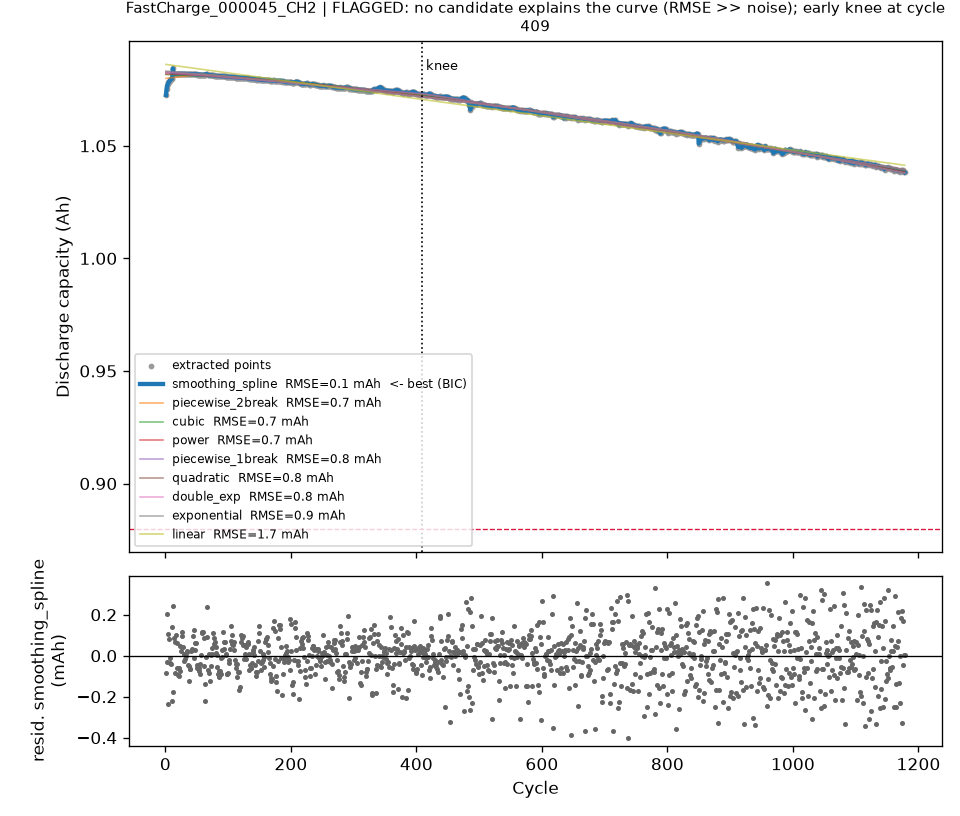

---

# FastCharge_000045_CH3

**call** `get_cell_overview({"cell_id": "FastCharge_000045_CH3"})`

```json
{"cell_id": "FastCharge_000045_CH3", "cycles": 1176, "eol_cycle": null, "reached_end_of_life": false, "q_start_Ah": 1.0829, "q_end_Ah": 1.0436, "noise_mAh": 0.09, "knee_cycle": 426, "knee_fraction_of_life": 0.362, "outliers_removed": 0, "recovery_jumps": 0, "best_parametric_law": "power", "runner_up": "cubic", "delta_bic_runner_up": 19.7, "misfit_z": -1.4, "knee_z": null, "shortlist_reasons": ["test ended 19% of the way to end of life; knee position not comparable", "degradation shape differs from the fleet (power beats double_exp by dBIC=282.4)"]}
```

**call** `check_end_of_life({"cell_id": "FastCharge_000045_CH3"})`

```json
{"reached_end_of_life": false, "eol_cycle": null, "last_cycle": 1176, "q_end_Ah": 1.0436, "fade_completed_fraction": 0.1937, "recent_fade_mAh_per_100_cycles": 4.7211, "cycles_to_end_of_life_at_recent_rate": 3465.2914}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000045_CH3", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.362, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 2.9, "n_cells": 139}
```

**agent:** **Cell:** FastCharge_000045_CH3  

**Investigation summary**

| Item | Value (from tools) |
|------|--------------------|
| Total cycles run | 1 176 |
| Capacity start → end | 1.0829 Ah → 1.0436 Ah |
| Fade completed | **19 %** of the 0.88 Ah EOL target (fade = 0.1937) |
| Recent fade rate | 4.72 mAh per 100 cycles |
| Projected cycles to EOL at current rate | ≈ 3 465 cycles |
| Knee cycle | 426 |
| Knee fraction of life | **0.362** (i.e., knee occurs at 36 % of the total life) |
| Fleet median knee fraction | 0.783 (75 %‑ile ≈ 0.80) |
| Cell percentile for knee fraction | **2.9 %** (far earlier than the fleet) |
| Outliers removed | 0 |
| Best parametric law | **Power** (runner‑up cubic, ΔBIC = 19.7) |
| Shape‑difference note (from shortlist) | Power law beats double‑exp by ΔBIC = 282.4 |
| Shortlist reasons | 1. Test ended 19 % of the way to EOL → knee not comparable  <br>2. Degradation shape differs from fleet |

**Interpretation**

1. **Test did not reach end‑of‑life.**  
   The cell has only faded 19 % toward the 0.88 Ah EOL threshold, and at the current fade rate it would need roughly another 3 500 cycles to reach EOL. Therefore the test stopped far before the cell’s true end‑of‑life.

2. **Knee position is not comparable.**  
   Because the test stopped early, the knee fraction (0.362) cannot be judged against the fleet’s typical knee fraction (≈0.78). The early knee is a consequence of the premature termination rather than an intrinsic early‑ageing behavior.

3. **Shape difference is noted, but it is secondary.**  
   The power‑law fit is strongly preferred over the double‑exponential for this cell, which the shortlist also flags. However, the primary reason for the cell’s appearance on the shortlist is the early termination of the test, making the shape comparison less reliable.

**Conclusion – Category**

The dominant issue is that the test stopped well before the cell reached its end‑of‑life, so the knee position and degradation‑shape metrics are not directly comparable to the fleet.  

**→ Category:** **test_ended_before_eol**  

No data‑quality problems (no outliers, no capacity jumps) are evident, and the early knee is explained by the premature test stop rather than genuine early ageing.

**verdict:** `{
 "category": "test_ended_before_eol",
 "confidence": "high",
 "evidence": [
  "Test stopped at cycle 1176 with only 19.37% of the required capacity fade (fade_completed_fraction=0.1937) and projected ~3465 cycles to reach EOL",
  "Knee occurred at cycle 426, i.e., knee_fraction=0.362, far earlier than fleet median knee_fraction=0.783 (cell_percentile=2.9%)",
  "No outliers or recovery jumps were removed (outliers_removed=0, recovery_jumps=0)",
  "Best parametric law is power, but shape comparison is unreliable because the test ended early"
 ],
 "recommended_action": "Continue cycling this cell to its true end\u2011of\u2011life to obtain comparable knee and degradation\u2011shape metrics."
}`


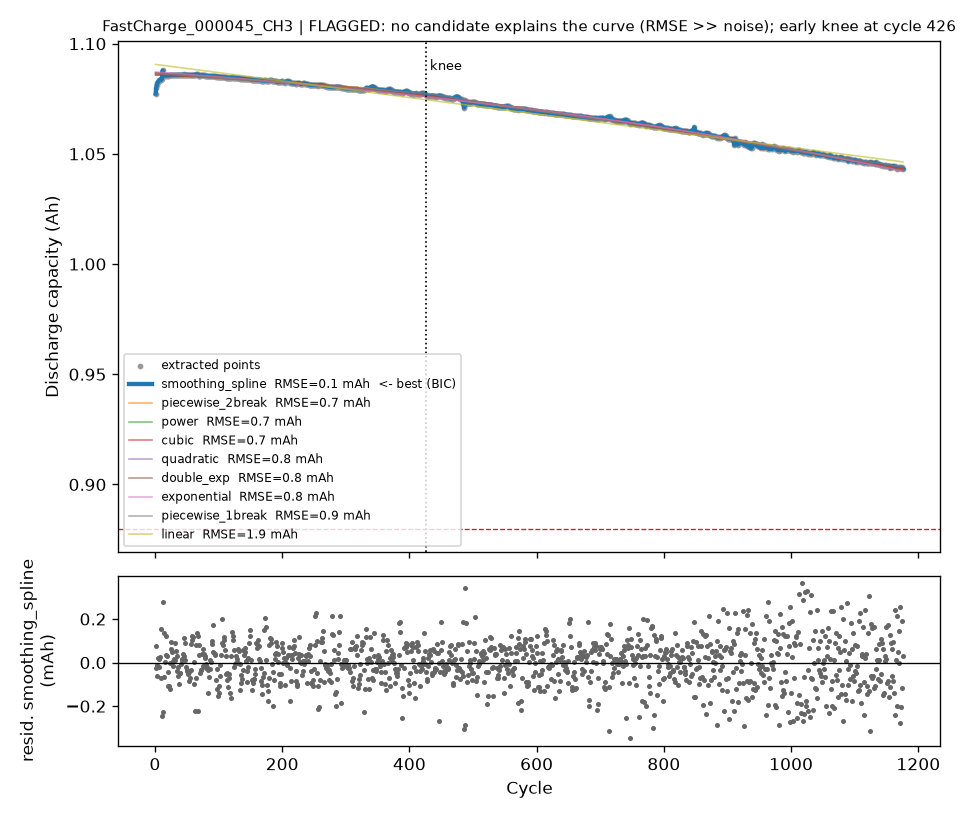

---

# FastCharge_000062_CH47

**call** `get_cell_overview({"cell_id": "FastCharge_000062_CH47"})`

```json
{"cell_id": "FastCharge_000062_CH47", "cycles": 446, "eol_cycle": 429, "reached_end_of_life": true, "q_start_Ah": 1.0761, "q_end_Ah": 0.8486, "noise_mAh": 0.2, "knee_cycle": 342, "knee_fraction_of_life": 0.797, "outliers_removed": 4, "recovery_jumps": 0, "best_parametric_law": "exponential", "runner_up": "double_exp", "delta_bic_runner_up": 5.9, "misfit_z": 0.28, "knee_z": 0.52, "shortlist_reasons": ["4 outlier cycles removed"]}
```

**call** `locate_outliers({"cell_id": "FastCharge_000062_CH47"})`

```json
{"outliers": 4, "per_quarter_of_test": [0, 0, 0, 0], "first_cycle": 447.0, "last_cycle": 450.0, "fraction_below_trend": 1.0, "median_deviation_mAh": -28.3114, "recovery_jumps": 0}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000062_CH47", "metric": "outliers"})`

```json
{"metric": "outliers", "cell_value": 4.0, "fleet_median": 1.0, "fleet_p25": 0.0, "fleet_p75": 1.0, "cell_percentile": 95.7, "n_cells": 139}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000062_CH47", "metric": "knee_fraction_of_life"})`

```json
{"error": "metric must be one of ['knee_fraction', 'rmse_mAh', 'noise_mAh', 'cycles', 'eol_cycle', 'fade_rate_mAh_per_100', 'outliers']"}
```

**agent:** **Category:** **data_quality**

**Why:**  
- The cell was shortlisted because **4 outlier cycles were removed** (the only listed shortlist reason).  
- Those outlier cycles occur after the recorded test (cycles 447‑450, while the test ends at cycle 446) and each deviates by **≈ ‑28 mAh** from the trend – a large, one‑sided dip.  
- Compared with the fleet, **4 outliers place the cell in the 95.7 th percentile** (fleet median = 1, 75 %‑tile = 1), far above the typical number of outliers.  

No other metrics (noise, knee position, fit quality) are unusual, and the test did reach end‑of‑life (EOL at cycle 429, knee at 342). The dominant issue is the abnormal outlier segment, indicating a measurement or equipment problem rather than genuine early ageing or an unusual degradation law.

**verdict:** `{
 "category": "data_quality",
 "confidence": "high",
 "evidence": [
  "The test recorded 446 cycles and reached end\u2011of\u2011life at cycle 429 (eol_cycle=429).",
  "4 outlier cycles were removed (outliers=4), far above the fleet median of 1 (cell_percentile=95.7).",
  "These outliers occur at cycles 447\u2011450, after the test end, and deviate by -28.3114\u202fmAh from the trend."
 ],
 "recommended_action": "Review the measurement setup for cycles 447\u2011450 and consider re\u2011testing or discarding this cell's data."
}`


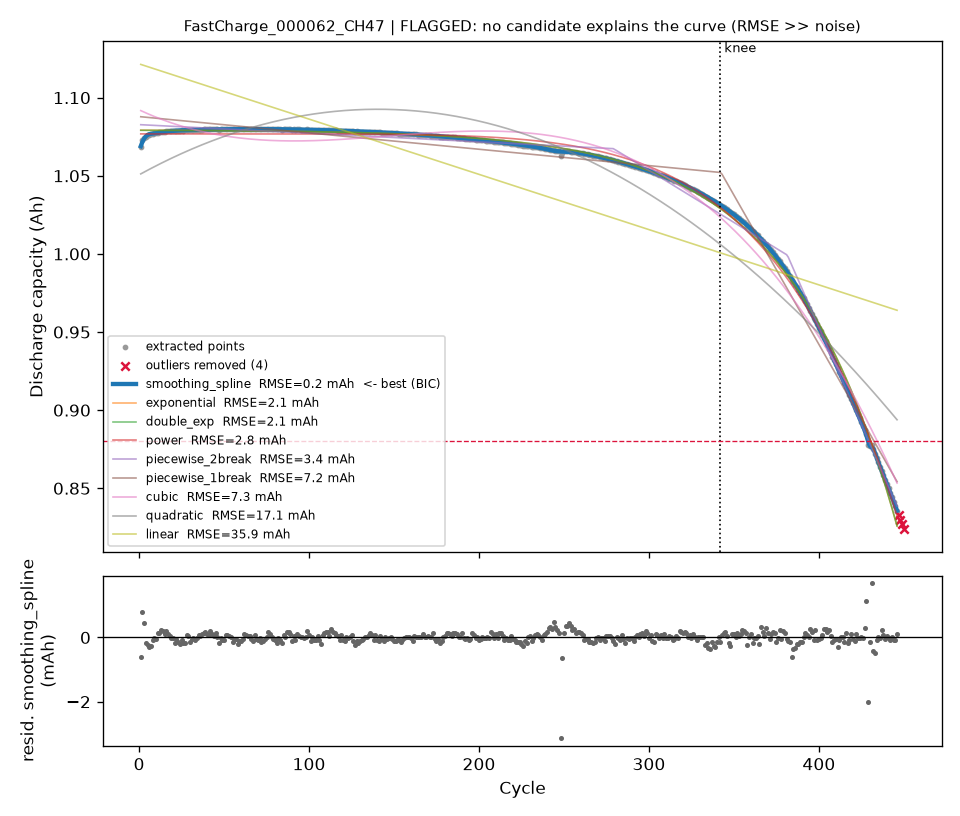

---

# FastCharge_000068_CH38

**call** `get_cell_overview({"cell_id": "FastCharge_000068_CH38"})`

```json
{"cell_id": "FastCharge_000068_CH38", "cycles": 500, "eol_cycle": 478, "reached_end_of_life": true, "q_start_Ah": 1.0774, "q_end_Ah": 0.8393, "noise_mAh": 0.21, "knee_cycle": 377, "knee_fraction_of_life": 0.789, "outliers_removed": 3, "recovery_jumps": 0, "best_parametric_law": "power", "runner_up": "double_exp", "delta_bic_runner_up": 64.6, "misfit_z": 0.7, "knee_z": 0.22, "shortlist_reasons": ["degradation shape differs from the fleet (power beats double_exp by dBIC=64.6)", "3 outlier cycles removed"]}
```

**call** `locate_outliers({"cell_id": "FastCharge_000068_CH38"})`

```json
{"outliers": 3, "per_quarter_of_test": [0, 1, 0, 0], "first_cycle": 247.0, "last_cycle": 503.0, "fraction_below_trend": 1.0, "median_deviation_mAh": -22.2052, "recovery_jumps": 0}
```

**call** `compare_to_fleet({"cell_id": "FastCharge_000068_CH38", "metric": "knee_fraction"})`

```json
{"metric": "knee_fraction", "cell_value": 0.789, "fleet_median": 0.783, "fleet_p25": 0.7525, "fleet_p75": 0.799, "cell_percentile": 62.6, "n_cells": 139}
```

**agent:** **Category:** unusual_shape  

**Why:** The cell’s degradation follows a different parametric law than the fleet. While the fleet’s best‑fit law is a double‑exponential, this cell is best described by a power‑law, beating the double‑exp by a large ΔBIC of 64.6. Its knee occurs at 0.789 of its life, essentially median for the fleet, and the test reached end‑of‑life (EOL cycle 478 of 500). The three outlier cycles are isolated and do not dominate the overall trend, so the primary reason it stands out is the atypical degradation shape.

**verdict:** `{
 "category": "unusual_shape",
 "confidence": "high",
 "evidence": [
  "Best parametric law is \"power\" beating double_exp by \u0394BIC=64.6, indicating a different degradation shape.",
  "Knee occurs at cycle 377, which is 0.789 of life (fleet median 0.783, percentile 62.6%).",
  "Test reached end\u2011of\u2011life (eol_cycle=478 of 500 cycles) with 3 outlier cycles removed, which are isolated."
 ],
 "recommended_action": "Review the cell\u2019s charge protocol and material batch to understand why a power\u2011law fits better than the fleet\u2019s double\u2011exponential model."
}`


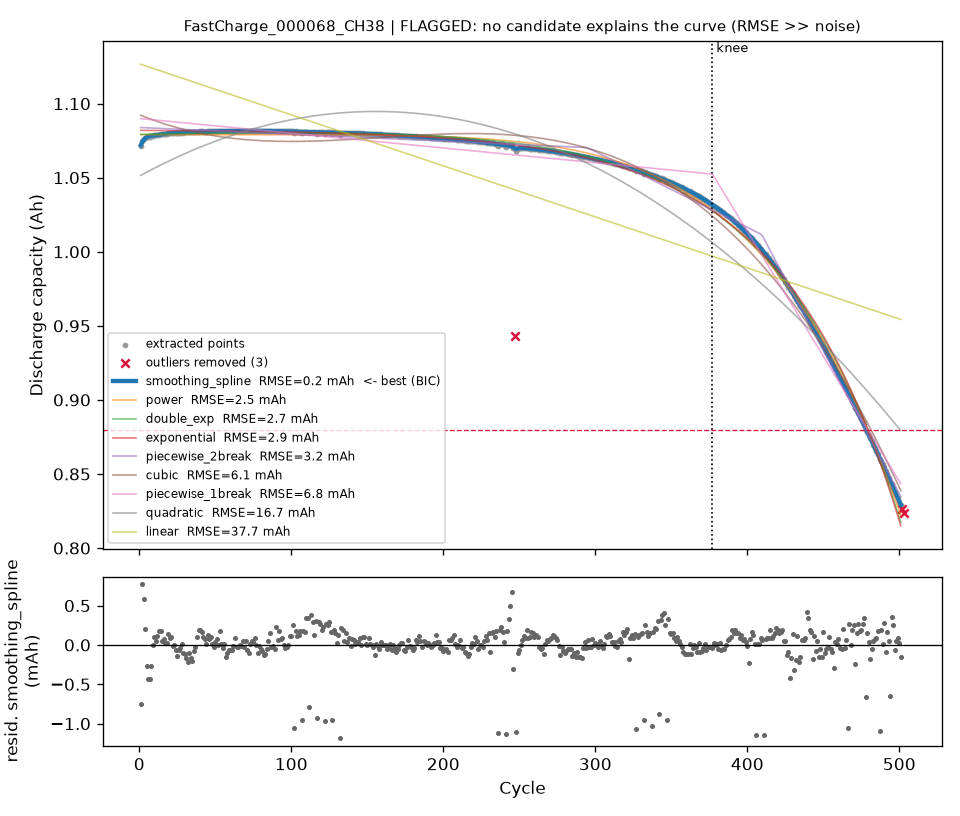

---

In [22]:
for cell in verdicts["cell_id"]:
    path = f"{cfg.out_dir}/traces/{cell}.md"
    if os.path.exists(path):
        display(Markdown(open(path).read()))
        display(Image(f"{cfg.plot_dir}/{cell}.png", width=600))
        display(Markdown("---"))

## Keeping this run

To publish this run with its outputs: in Colab, **File → Save a copy in GitHub** (or **File → Download → .ipynb**
and commit it as `notebooks/colab_investigator.ipynb`). In Jupyter, just save and commit.
The API key is read from a secret and never printed, so it is not stored in the notebook.